# 02 — Chapman-Shaoxing: SNOMED-CT Taxonomy, Duplicate Code Mappings & Co-occurrence

Auditing `ConditionNames_SNOMED-CT.csv` (`63` entries) and multi-label SNOMED-CT diagnoses across all `45,152` records:
- Detecting many-to-one SNOMED-CT code mappings inside `ConditionNames_SNOMED-CT.csv` (e.g., `164865005` mapped to `MI`, `MIBW`, `MIFW`, `MILW`, `MISW`).
- Top 20 diagnoses, multi-label co-occurrence heatmap, `SR` + arrhythmia conflicts, and prevalence vs age decades.

ConditionNames_SNOMED-CT.csv rows: 63 | unique SNOMED codes: 55 | duplicate-code rows: 12


,Acronym Name,Full Name,Snomed_CT
27,MIBW,myocardial infraction in back wall,164865005
28,MIFW,Myocardial infgraction in the front wall,164865005
26,MI,myocardial infarction,164865005
29,MILW,Myocardial infraction in the lower wall,164865005
30,MISW,Myocardial infraction in the side wall,164865005
21,LFBBB,left front bundle branch block,164909002
19,LBBB,left bundle branch block,164909002
20,LBBBB,left back bundle branch block,164909002
50,WAVN,Wandering in the atrioventricalualr node,195101003
62,SAAWR,Sinus Atrium to Atrial Wandering Rhythm,195101003


,SNOMED_CT,Abbreviation,Count
0,426177001,SB,16148
1,426783006,SR,8125
2,164890007,AF,8060
3,427084000,ST,7249
4,164934002,TWC,6999
5,55827005,55827005,5352
6,55930002,55930002,4209
7,59931005,TWO,2854
8,427393009,SA,2550
9,164889003,AFIB,1780


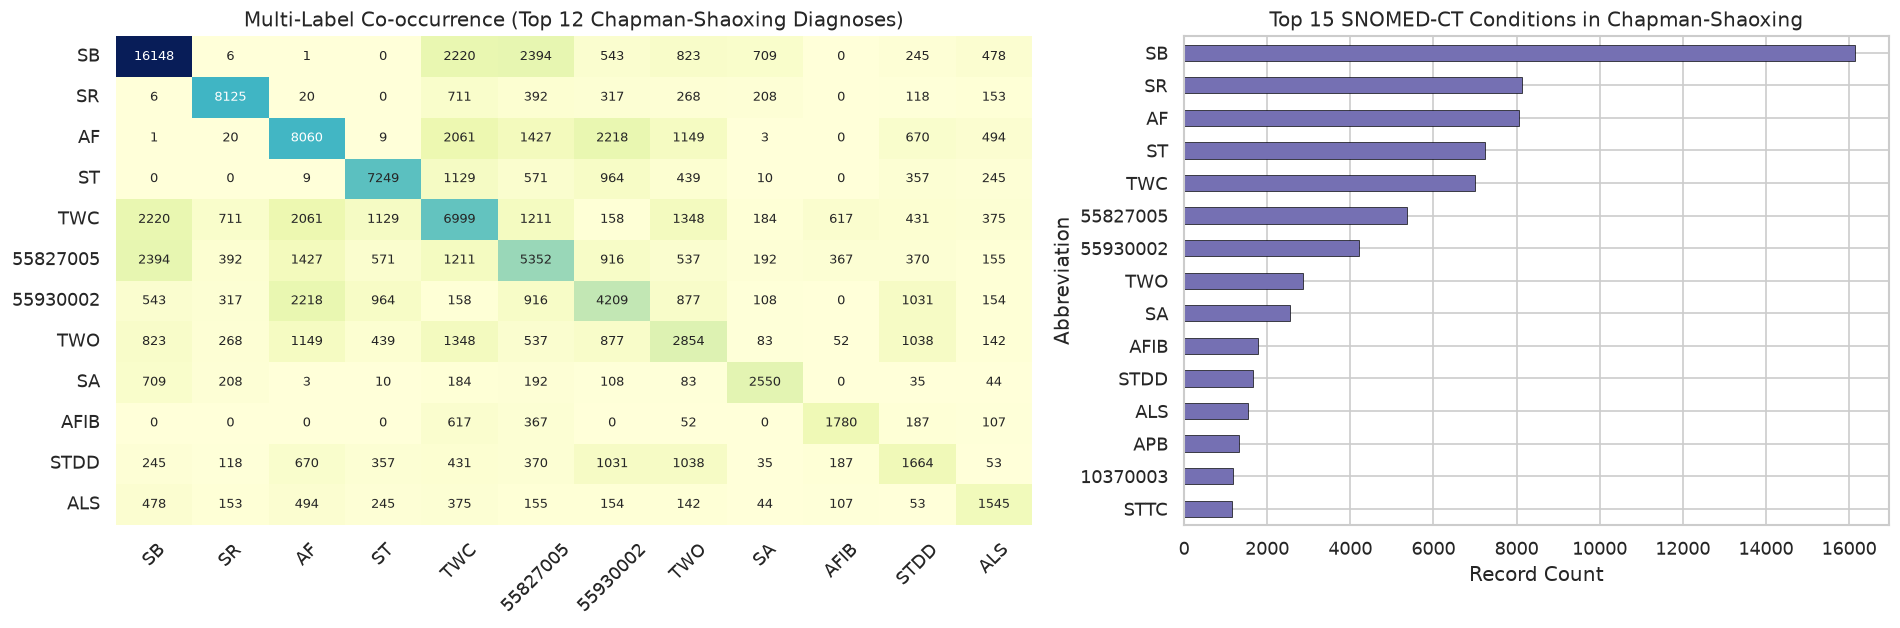

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "chapman_shaoxing" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate chapman_shaoxing/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from chapman_shaoxing import ChapmanShaoxingDataset

CHAPMAN_DIR = REPO_ROOT / "chapman_shaoxing"
DATA_DIR = CHAPMAN_DIR / "data"
QUALITY_DIR = CHAPMAN_DIR / "quality"
LEADS = ChapmanShaoxingDataset.LEADS

df = pd.read_csv(QUALITY_DIR / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")

from collections import Counter

cond_df = pd.read_csv(DATA_DIR / "ConditionNames_SNOMED-CT.csv")
cond_df.columns = cond_df.columns.str.strip()
dup_snomed = cond_df[cond_df.duplicated(subset=["Snomed_CT"], keep=False)].sort_values("Snomed_CT")
print(f"ConditionNames_SNOMED-CT.csv rows: {len(cond_df)} | unique SNOMED codes: {cond_df['Snomed_CT'].nunique()} | duplicate-code rows: {len(dup_snomed)}")
if len(dup_snomed) > 0:
    display(dup_snomed)

code_to_abbr = {}
for c, abbr in zip(cond_df["Snomed_CT"].astype(str), cond_df["Acronym Name"].astype(str)):
    code_to_abbr.setdefault(c.strip(), abbr.strip())

df["code_list"] = df["snomed_codes"].apply(lambda s: [x for x in s.split("|") if x])
counts = Counter(c for lst in df["code_list"] for c in lst)
top15 = [(c, code_to_abbr.get(c, c), cnt) for c, cnt in counts.most_common(15)]
top15_df = pd.DataFrame(top15, columns=["SNOMED_CT", "Abbreviation", "Count"])
display(top15_df)

top12_codes = [x[0] for x in top15[:12]]
top12_names = [x[1] for x in top15[:12]]
c2n = dict(zip(top12_codes, top12_names))
cooc = pd.DataFrame(0, index=top12_names, columns=top12_names)
for lst in df["code_list"]:
    pres = sorted({c2n[c] for c in lst if c in c2n})
    for a in pres:
        for b in pres:
            cooc.loc[a, b] += 1

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(cooc, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0], cbar=False, annot_kws={"size": 7.5})
axes[0].set_title("Multi-Label Co-occurrence (Top 12 Chapman-Shaoxing Diagnoses)")
axes[0].tick_params(axis="x", rotation=45)

top15_df.iloc[::-1].plot(kind="barh", x="Abbreviation", y="Count", legend=False, color="#7570b3", edgecolor="black", lw=0.4, ax=axes[1])
axes[1].set_xlabel("Record Count")
axes[1].set_title("Top 15 SNOMED-CT Conditions in Chapman-Shaoxing")

plt.tight_layout()
plt.show()